# Persons Involved in the Group

The five students are:
- Student 1
- Student 2
- Student 3
- Student 4
- Student 5

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [2]:
%matplotlib inline
%pylab inline
import pandas as pd
import torch
import matplotlib.pyplot as plt

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [3]:
# read data
daily_temp_brest = pd.read_csv('daily_temp_brest.csv')
print(daily_temp_brest)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]


Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

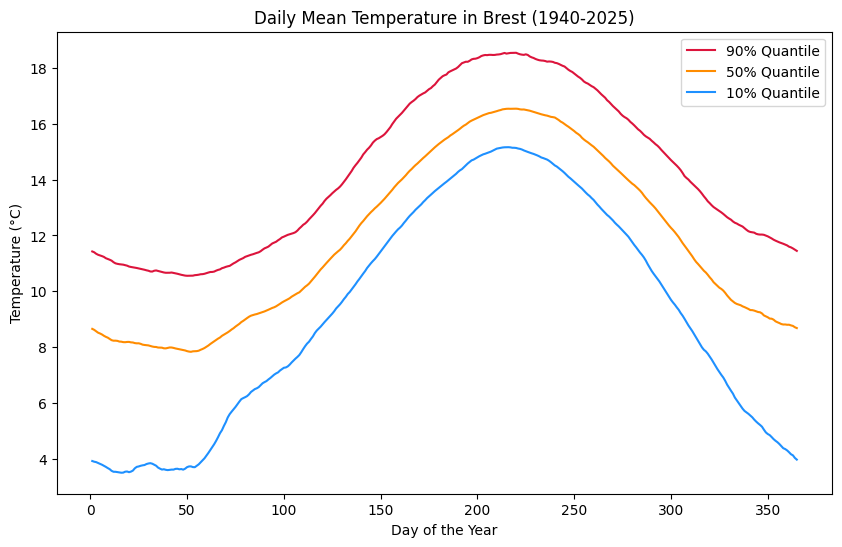

In [12]:
### TO DO ###
daily_temp_brest['day_of_year'] = pd.to_datetime(daily_temp_brest['valid_time']).dt.dayofyear
daily_temp = daily_temp_brest[daily_temp_brest['day_of_year']<=365]

quantiles = daily_temp.groupby('day_of_year')['mean'].quantile([0.1, 0.5, 0.9]).unstack()

quantiles_padded = pd.concat([quantiles.iloc[-15:], quantiles, quantiles.iloc[:15]])
quantiles_smooth = quantiles_padded.rolling(window=30, center=True).mean().iloc[15:-15]

plt.figure(figsize=(10, 6))
plt.plot(quantiles_smooth.index, quantiles_smooth[0.9], label='90% Quantile', color='crimson')
plt.plot(quantiles_smooth.index, quantiles_smooth[0.5], label='50% Quantile', color='darkorange')
plt.plot(quantiles_smooth.index, quantiles_smooth[0.1], label='10% Quantile', color='dodgerblue')

plt.title('Daily Mean Temperature in Brest (1940-2025)')
plt.xlabel('Day of the Year')
plt.ylabel('Temperature (°C)')
plt.legend()

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

In [17]:
### TO DO ###
daily_temp.loc[daily_temp['day_of_year'] == 366, 'day_of_year'] = 365

clim = daily_temp.groupby('day_of_year')['mean'].agg(q90=lambda x: x.quantile(0.9), q50=lambda x: x.quantile(0.5))

clim_padded = pd.concat([clim.iloc[-15:], clim, clim.iloc[:15]])
clim_smooth = clim_padded.rolling(window=30, center=True).mean().iloc[15:-15]

daily_temp = daily_temp.merge(clim_smooth, on='day_of_year', how='left')
daily_temp['is_hw_day'] = daily_temp['mean'] > daily_temp['q90']
daily_temp['anomaly'] = daily_temp['mean'] - daily_temp['q50']

daily_temp['hw_group'] = (~daily_temp['is_hw_day']).cumsum()
hw_days = daily_temp[daily_temp['is_hw_day']]

hw_events = hw_days.groupby('hw_group').agg(
    start_date=('valid_time', 'min'),
    end_date=('valid_time', 'max'),
    duration=('valid_time', 'count'),
    intensity=('anomaly', 'mean')
).reset_index(drop=True)


Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

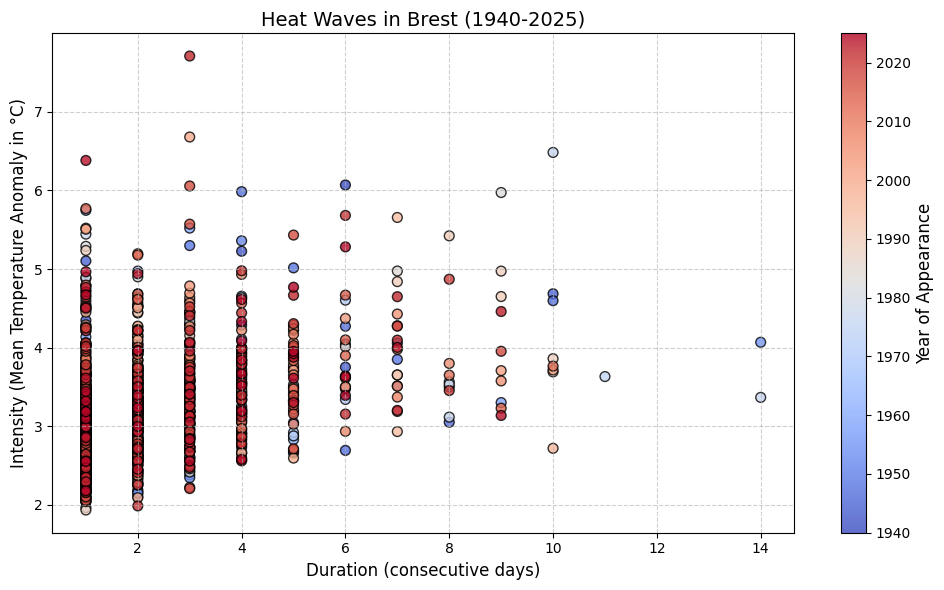

In [19]:
hw_events['year'] = pd.to_datetime(hw_events['start_date']).dt.year

# 8. Create the scatter plot
plt.figure(figsize=(10, 6))
sc = plt.scatter(hw_events['duration'], hw_events['intensity'], 
                 c=hw_events['year'], cmap='coolwarm', 
                 alpha=0.8, edgecolor='k', s=50)

# 9. Format the visual elements
cbar = plt.colorbar(sc)
cbar.set_label('Year of Appearance', fontsize=12)

plt.title('Heat Waves in Brest (1940-2025)', fontsize=14)
plt.xlabel('Duration (consecutive days)', fontsize=12)
plt.ylabel('Intensity (Mean Temperature Anomaly in °C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [20]:
# read data
yearly_temp_brest = pd.read_csv('yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

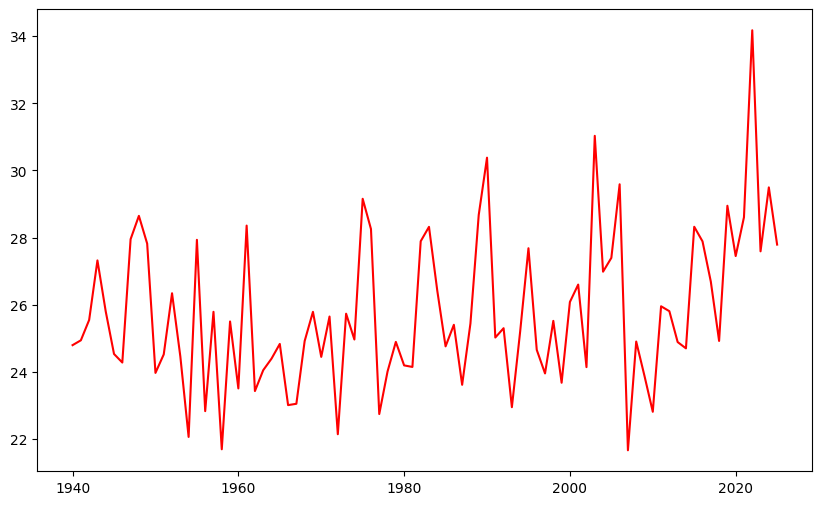

In [24]:
### TO DO ###
yearly_temp_brest['valid_time'] = pd.to_datetime(yearly_temp_brest['valid_time'])
plt.figure(figsize=(10, 6))
plt.plot(yearly_temp_brest['valid_time'].dt.year, yearly_temp_brest['max'], color='r', markersize=4)
plt.show()

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

In [55]:
### TO DO ###
import numpy as np 
T_max = yearly_temp_brest['max']
co2 = yearly_temp_brest['co2']
yearly_temp_brest['max_lisse'] = yearly_temp_brest['max'].rolling(window=10, center=True).mean()

corr_initiale = T_max.corr(co2)
print(f"Corrélation de base (sans transformation) : {corr_initiale:.4f}")
corr_lissee = yearly_temp_brest['max_lisse'].corr(yearly_temp_brest['co2'])
print(f"Corrélation après lissage : {corr_lissee:.4f}")

transformations = {
    "Originale": lambda x: x,
    "Logarithmique (log)": lambda x : np.log(x),
    "Racine carrée (sqrt)": lambda x: np.sqrt(x),
    "Carré (x^2)": lambda x: x**2,
    "Cube (x^3)": lambda x: x**3,
    "Inverse (1/x)": lambda x: 1/x
}

resultats = []
for nom_tmax, f_tmax in transformations.items():
    for nom_co2, f_co2 in transformations.items():
        try:
            # Application de la transformation
            tmax_trans = f_tmax(T_max)
            co2_trans = f_co2(co2)
            
            # Calcul de la corrélation
            corr = tmax_trans.corr(co2_trans)
            resultats.append({
                'Trans_Tmax': nom_tmax,
                'Trans_CO2': nom_co2,
                'Correlation': corr,
                'Abs_Correlation': abs(corr)
            })
        except:
            continue

Corr_resultats = pd.DataFrame(resultats)
Corr_resultats = Corr_resultats.sort_values(by='Abs_Correlation', ascending=False).reset_index(drop=True)

print(Corr_resultats[['Trans_Tmax', 'Trans_CO2', 'Correlation']])

Corrélation de base (sans transformation) : 0.3143
Corrélation après lissage : 0.5742
              Trans_Tmax             Trans_CO2  Correlation
0             Cube (x^3)            Cube (x^3)     0.342425
1            Carré (x^2)            Cube (x^3)     0.338996
2              Originale            Cube (x^3)     0.334061
3             Cube (x^3)           Carré (x^2)     0.332737
4   Racine carrée (sqrt)            Cube (x^3)     0.331101
5            Carré (x^2)           Carré (x^2)     0.329334
6    Logarithmique (log)            Cube (x^3)     0.327851
7              Originale           Carré (x^2)     0.324462
8             Cube (x^3)             Originale     0.322543
9   Racine carrée (sqrt)           Carré (x^2)     0.321548
10         Inverse (1/x)            Cube (x^3)    -0.320584
11           Carré (x^2)             Originale     0.319149
12   Logarithmique (log)           Carré (x^2)     0.318350
13            Cube (x^3)  Racine carrée (sqrt)     0.317276
14            

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.

In [25]:
# read data
yearly_future_co2 = pd.read_csv('yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


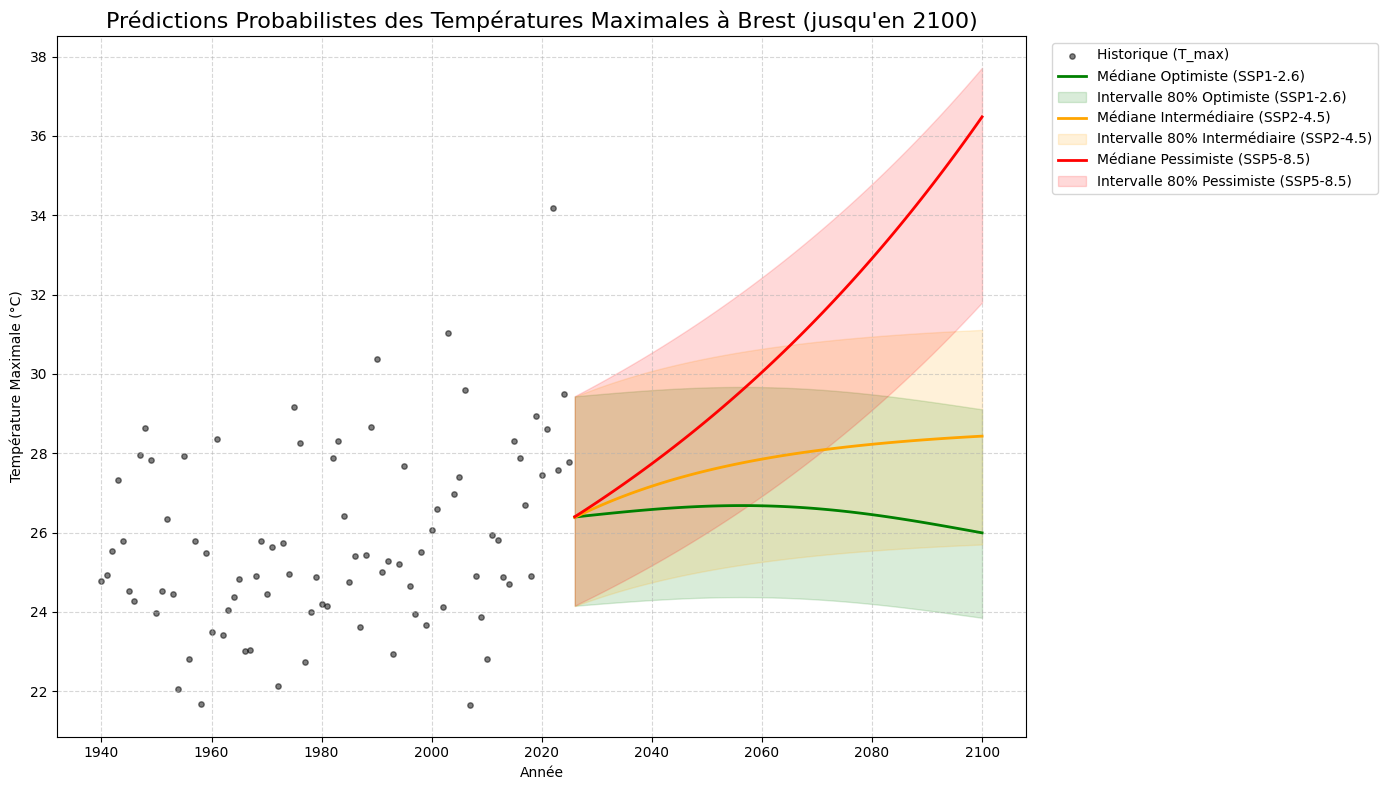

In [72]:
### TO DO ###
from sklearn.linear_model import QuantileRegressor
import warnings
warnings.filterwarnings('ignore')

annees_hist = pd.to_datetime(yearly_temp_brest['valid_time']).dt.year
annees_fut = pd.to_datetime(yearly_future_co2['valid_time']).dt.year

X_hist = (yearly_temp_brest['co2'].values.reshape(-1, 1))
y_hist = (yearly_temp_brest['max'].values)

# Entrainement et Régularisation des données grace à alpha pour pénaliser les pentes trop raides
model_q10 = QuantileRegressor(quantile=0.1, alpha=0.0, solver='highs').fit(X_hist, y_hist)
model_q50 = QuantileRegressor(quantile=0.5, alpha=0.0, solver='highs').fit(X_hist, y_hist)
model_q90 = QuantileRegressor(quantile=0.9, alpha=0.0, solver='highs').fit(X_hist, y_hist)

plt.figure(figsize=(14, 8))
plt.scatter(annees_hist, y_hist, color='black', alpha=0.5, s=15, label='Historique (T_max)')

scenarios = ['ssp1-2.6', 'ssp2-4.5', 'ssp5-8.5']
couleurs = {'ssp1-2.6': 'green', 'ssp2-4.5': 'orange', 'ssp5-8.5': 'red'}
labels = {'ssp1-2.6': 'Optimiste (SSP1-2.6)', 
          'ssp2-4.5': 'Intermédiaire (SSP2-4.5)', 
          'ssp5-8.5': 'Pessimiste (SSP5-8.5)'}

for ssp in scenarios:
    X_fut = (yearly_future_co2[ssp].values.reshape(-1, 1))
    
    # Génération des 3 courbes (basse, médiane, haute)
    # L'apprentissage des quantiles est indépendant, ce qui peut provoquer du quantile crossing  (pred_50 > pred_90)
    pred_10 = model_q10.predict(X_fut)
    pred_50 = model_q50.predict(X_fut)
    pred_90 = model_q90.predict(X_fut)
    
    # Tri des prédictions pour corriger le quantile crossing
    predictions = np.array([pred_10, pred_50, pred_90])
    predictions_triees = np.sort(predictions, axis=0)
    pred_10_corrige = predictions_triees[0]
    pred_50_corrige = predictions_triees[1]
    pred_90_corrige = predictions_triees[2]
    
    
    # Tracé de la médiane
    plt.plot(annees_fut, pred_50_corrige, color=couleurs[ssp], linewidth=2, label=f'Médiane {labels[ssp]}') 
    
    # Remplissage de la zone de probabilité (Intervalle à 80%)
    plt.fill_between(annees_fut, pred_10_corrige, pred_90_corrige, color=couleurs[ssp], alpha=0.15, label=f'Intervalle 80% {labels[ssp]}')
    
plt.title("Prédictions Probabilistes des Températures Maximales à Brest (jusqu'en 2100)", fontsize=16)
plt.xlabel("Année")
plt.ylabel("Température Maximale (°C)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**La méthode choisie : La Régression Quantile.**

Plutôt que de minimiser lA MSE , la régression quantile minimise la fonction de perte Pinball Loss pour chaque quantile. Mathématiquement, pour estimer le quantile d'ordre $\tau$ (par exemple $\tau = 0.9$ pour le 90ème quantile), on cherche les coefficients $\beta$ qui minimisent :

$$ L_\tau = \sum_{y_i \ge x_i \beta} \tau |y_i - x_i \beta| + \sum_{y_i < x_i \beta} (1 - \tau) |y_i - x_i \beta| $$

La régression linéaire prédit la moyenne conditionnelle de la variable température. Mais le changement climatique ne se contente pas de décaler la température moyenne, ca accroît la volatilité et amplifie les extrémités. Prédire une température maximale moyenne ne permet pas de capturer ces informations.

La régression quantile résout ce problème en estimant des quantiles spécifiques de la distribution des températures. En entraînant des modèles pour les quantiles à 10 %, 50 % (la médiane) et 90 %, nous établissons une intervalle de probabilité de 80 %. Pour toute année future, conditionnellement au niveau de CO2, il y a une probabilité de 80 % que la température maximale se situe à l'intérieur de cette bande. Par contre l'entrainement indépendant des modèles de chaque quantile peut provoquer des incohérences par exemple lorsque la température prédite par le modèle quantile 50% est supérieure à celle prédite par celui du quantile 90%. Dans ce cas il faut effectuer un tri des prédictions pour guarantir que les médianes restent cohérentes dans les intervalles à 80% respectifs, c'est ce qui provoque un brusque changement de direction dans la courbe de la médiane pessimiste.

Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

Génération des distributions (entraînement de 99 quantiles)...

--- Probabilités de dépasser 40°C en 2100 ---
Scénario SSP1-2.6 : 0.0 %
Scénario SSP2-4.5 : 0.0 %
Scénario SSP5-8.5 : 1.0 %


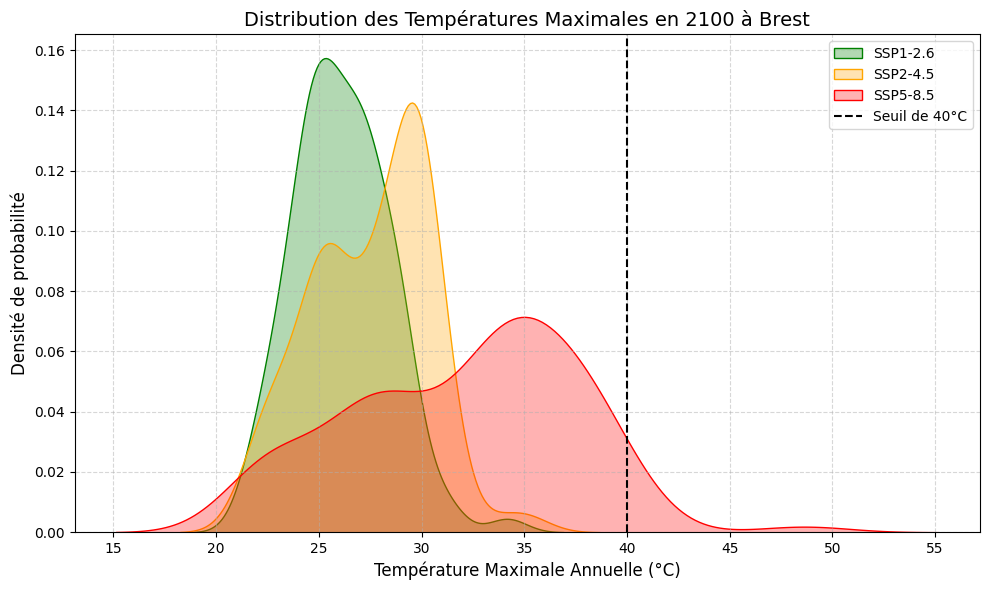

In [73]:
### TO DO ###
import seaborn as sns
co2_2100 = {
    'SSP1-2.6': yearly_future_co2.loc[yearly_future_co2['valid_time'].str.startswith('2100'), 'ssp1-2.6'].values[0],
    'SSP2-4.5': yearly_future_co2.loc[yearly_future_co2['valid_time'].str.startswith('2100'), 'ssp2-4.5'].values[0],
    'SSP5-8.5': yearly_future_co2.loc[yearly_future_co2['valid_time'].str.startswith('2100'), 'ssp5-8.5'].values[0]
}

quantiles = np.linspace(0.01, 0.99, 99)
distributions_2100 = {'SSP1-2.6': [], 'SSP2-4.5': [], 'SSP5-8.5': []}

print("Génération des distributions (entraînement de 99 quantiles)...")
models = []
for q in quantiles:
    qr = QuantileRegressor(quantile=q, alpha=1, solver='highs')
    qr.fit(X_hist, y_hist)
    models.append(qr)
    for ssp, co2_val in co2_2100.items():
        X_fut_2100 = np.array([[co2_val]])
        prediction = qr.predict(X_fut_2100)[0]
        distributions_2100[ssp].append(prediction)
        
plt.figure(figsize=(10, 6))
couleurs = {'SSP1-2.6': 'green', 'SSP2-4.5': 'orange', 'SSP5-8.5': 'red'}
print("\n--- Probabilités de dépasser 40°C en 2100 ---")

for ssp in distributions_2100.keys():
    preds = np.sort(distributions_2100[ssp]) # Tri des prédictions
    sns.kdeplot(preds, color=couleurs[ssp], label=ssp, fill=True, alpha=0.3) # Tracé de la distribution de probabilité (KDE)
    prob_sup_40 = np.mean(preds > 40.0) * 100 # Calcul de la probabilité empirique : proportion des 99 quantiles > 40°C
    print(f"Scénario {ssp} : {prob_sup_40:.1f} %")
    
plt.axvline(x=40, color='black', linestyle='--', label='Seuil de 40°C')
plt.title('Distribution des Températures Maximales en 2100 à Brest', fontsize=14)
plt.xlabel('Température Maximale Annuelle (°C)', fontsize=12)
plt.ylabel('Densité de probabilité', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

In [74]:
df_test = yearly_temp_brest[(yearly_temp_brest['valid_time'] >= '2001-01-01') & (yearly_temp_brest['valid_time'] <= '2025-12-31')].copy()

def calculer_crps_fast(tirages, vraie_valeur):
    N = len(tirages)
    distance_verite = np.mean(np.abs(tirages - vraie_valeur))
    
    # Étalement des tirages
    # L'équation mathématique vectorisée évite la matrice 10000x10000
    tirages_tries = np.sort(tirages)
    poids = 2 * np.arange(N) - N + 1
    etalement = (2 / (N**2)) * np.sum(poids * tirages_tries)
    
    crps = distance_verite - (0.5 * etalement)
    return crps


scores_annuels = []
for index, row in df_test.iterrows():
    co2_annee = np.array([[row['co2']]])
    vraie_tmax = row['max']
    preds_99 = [modele.predict(co2_annee)[0] for modele in models]
    tirages_10k = np.random.choice(preds_99, size=10000, replace=True)
    crps_annee = calculer_crps_fast(tirages_10k, vraie_tmax)
    scores_annuels.append(crps_annee)

crps_final = np.mean(scores_annuels)

print(f"\nCRPS final moyenné sur 2001-2025 : {crps_final:.4f} °C")


CRPS final moyenné sur 2001-2025 : 1.4905 °C


Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).

In [ ]:
### TO DO ###